# Retail Sales - Statistics and Hypothesis Testing

## Business Requirement 3

**Business Question:**
Does the data show a statistically significant difference in average total weekly sales between holiday and non-holiday weeks, and is the difference big enough to have a meaningful business impact?

### Purpose

This notebook applies statistical and probabilistic methods to investigate whether average sales vary significantly between holiday weeks and non-holiday weeks. 

This analysis uses the cleaned retail dataset, and included wil be descriptive statistics, probability calculations, hypothesis testing and finally business evaluation. 

### Statistical Concepts Used

- **Aggregation:** 
  - The process of gathering raw data from multiple sources. 
  - It uses statistical functions such as (sums, averages,counts etc).
  - For this project it was used to combine individual department sales into total retail sales for each week.

- **Mean:**
  - The mean is the average of a set of numbers.
  - To find the mean all values gets added up in the data and then that total gets divided by the number of values.
  - In this analysis it was calculated y dividing total sales by the number of observations.

- **Median:**
  - The median is the exact middle value of a dataset when it is sorted in order.
  - to calculate it sort the numbers from lowest to highest, if it is an odd count pick the number in the middle, and if it is a even count then the median is average of the two middle numbers.
  - In this analysis it is the middle sales value.

- **Standard Deviation:**
  - This a measure of how widely data values are scattered away from the mean.
  - To calculate it subtract the mean from each data point and square it, average the square and find the mean of that (variance) then take the square root of that variance.

- **Probability:**
  - Measures how likely an event is to occur.
  - Expressed as a number between 0 and 1
  - This will be used to calculate the propotion of observed weeks known as holidays.

- **Null Hypothesis (H0):**
  - A default assumption that there is no effect or no relationship.
  - A statement that is tested.
  - In this research it will assume that there is no difference in mean sales between holiday and non-holiday periods. 

- **Alternative Hypothesis (H1):**
  - The opposite of Null Hypothesis, there is an effect or relationship
  - The claim that is supported in the testing
  - It will assume there is a difference in mean sales between holiday and non-holiday weeks.

- **P-Value:**
  - Is the likelihood of test results happening strictly by coincidence
  - The probability of getting a result at least as extreme as the observed result, assuming the null hypothesis is true

- **Significance Level (a = 0.05):**
  - The pre determined cutoff limit for deciding whether to reject the null hypothesis.
  - If the p-value is below this limit, statistical evidence is enough to reject it.
  - It acts as a strict boundary to prevent false conclusions.

  ## Statistical Method

  Welch's independent-samples t-test will be used to compare mean total weekly sales between holiday and non-holiday periods,

  Prior to running the test, sales numbers will be aggregated by date so that each week counts as one independent observation instead of multiple department entries. 

In [1]:
import pandas as pd
from pathlib import Path

# Find the project folder
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Load the cleaned dataset from BR1/BR2
file_path = project_root / "data" / "cleaned" / "retail_sales_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["Date"])

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (421570, 22)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Year,Month,Week,Temperature,Fuel_Price,...,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Markdown_Data_Available,Total_MarkDown,Type,Size,Markdown_Activity
0,1,1,2010-02-05,24924.50,False,2010,2,5,42.31,2.572,...,NaN,NaN,NaN,211.096358,8.106,False,NaN,A,151315,NaN
1,1,1,2010-02-12,46039.49,True,2010,2,6,38.51,2.548,...,NaN,NaN,NaN,211.242170,8.106,False,NaN,A,151315,NaN
2,1,1,2010-02-19,41595.55,False,2010,2,7,39.93,2.514,...,NaN,NaN,NaN,211.289143,8.106,False,NaN,A,151315,NaN
3,1,1,2010-02-26,19403.54,False,2010,2,8,46.63,2.561,...,NaN,NaN,NaN,211.319643,8.106,False,NaN,A,151315,NaN
4,1,1,2010-03-05,21827.90,False,2010,3,9,46.50,2.625,...,NaN,NaN,NaN,211.350143,8.106,False,NaN,A,151315,NaN


## Preparing Data For Statistical Analysis

### Aggregating Weekly Sales

The original dataset tracks weekly sales for separate departments across 45 individual stores.

For this hypothesis test, these records will be aggregated to calculate total sales across all store locations for each week.

This gives us one clean data point per week, letting us compare holiday and non-holiday weekly sales without falsely treating individual department records as independent observations.

In [2]:
# Calculate total sales all stores for each week
weekly_sales = (df.groupby("Date", as_index=False)
.aggregate(Weekly_Sales=("Weekly_Sales", "sum"),
IsHoliday=("IsHoliday", "first"))
) 

print("Number of weeks:", len(weekly_sales))

weekly_sales.head()

Number of weeks: 143


,Date,Weekly_Sales,IsHoliday
0,2010-02-05,49750740.50,False
1,2010-02-12,48336677.63,True
2,2010-02-19,48276993.78,False
3,2010-02-26,43968571.13,False
4,2010-03-05,46871470.30,False


## Descriptive Statistics: Holiday Versus Non-Holiday

A comparison between, the mean, median, standard deviation and number of weeks in each group, will take place.

These statistics will provide insights into typical weekly sales, sales variability and whether the two groups have different sample size. 


In [3]:
holiday_summary = (weekly_sales.groupby("IsHoliday")["Weekly_Sales"]
.aggregate(["mean", "median", "std","count"])
.round(2)
) 

holiday_summary

,mean,median,std,count
IsHoliday,,,,
False,46856537.11,46128514.25,5083440.03,133
True,50529955.16,47833126.05,8642457.47,10


## Descriptive Statistics Findings 

The dataset consists of 143 weeks, of those weeks non-holiday weeks make up 113 weeks and holiday makes up 10 weeks. 

The average total weekly sales during the holiday was around 50.53 million, and 46.86 million during non-holiday weeks. 

Median and standard deviation was also higher during the holiday weeks, which suggest that typical sales are high but variation is greater. 

This analysis is not enough to draw conclusions therefore further statistical testing is needed. 

Calculating holiday probability and sales difference

In [4]:
# Probability of a randomly selected observed week being a holiday
holiday_probability = weekly_sales["IsHoliday"].mean()

# Difference in average weekly sales
holiday_mean = holiday_summary.loc[True, "mean"]
nonholiday_mean = holiday_summary.loc[False, "mean"]

sales_difference = holiday_mean - nonholiday_mean
percentage_difference = (sales_difference / nonholiday_mean) * 100

print(f"Holiday probability: {holiday_probability:.2%}")
print(f"Average weekly sales difference: {sales_difference:,.2f}")
print(f"Percentage difference: {percentage_difference:.2f}%")

Holiday probability: 6.99%
Average weekly sales difference: 3,673,418.05
Percentage difference: 7.84%


### Probability and Sales Difference Findings

Holiday periods made up 6.99% of the 143 total weeks recorded.

Average total weekly sales jumped by roughly 3.67 million during holiday weeks representing a 7.84% rise compared to non-holiday weeks. 

While this bump is important for inventory and staffing logistics, this difference alone does not establish statistical significance or a direct cause-and-effect relationship.

## Hypothesis Testing

Welch's independent-samples t-test will be used to determine whether mean total weekly sales differ between holiday and non-holiday weeks.

- **H0 (Null Hypothesis):** Mean weekly sales are equal for holiday and non-holiday weeks.
- **H1 (Alternative Hypothesis):** Mean weekly sales are different.
- **Significance Level:** α = 0.05.

Welch's t-test is well-suited for this comparison given the unequal sample sizes and differing standard deviations between the two groups.

If p ≤ 0.05: we reject H₀
If p > 0.05: we fail to reject H₀

In [5]:
from scipy.stats import ttest_ind

# Separate holiday and non-holiday weekly sales
holiday_sales = weekly_sales.loc[
    weekly_sales["IsHoliday"] == True, "Weekly_Sales"
]

nonholiday_sales = weekly_sales.loc[
    weekly_sales["IsHoliday"] == False, "Weekly_Sales"
]

# Welch's independent-samples t-test
t_statistic, p_value = ttest_ind(
    holiday_sales,
    nonholiday_sales,
    equal_var=False
)

print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

T-statistic: 1.3270
P-value: 0.2156


### Hypothesis Test Findings

Welch's t-test yielded a t-statistic of 1.3270 and a p-value of a 0.2156.

the p-value exceeds the 0.05 threshold, meaning that we failed to reject the null hypothesis.

Even though holiday weekly sales averaged 7.84% higher,the difference was not statistically significant.

This means that there is not enough statistical evidence to conclude that mean weekly sales differ between holiday and non-holiday weeks.

There were also some limitations with this analysis, one such being, uneven sample split, where holiday weeks accounted for only a tiny fraction of the data (10 holiday weeks compared to 133 non-holiday weeks). The unequal sample size could be restrciting statistical power, in addition to other factors that could also have an affect. 




In [6]:
# Calculate Cohen's d.

import numpy as np

# Calculate the pooled standard deviation
n1 = len(holiday_sales)
n2 = len(nonholiday_sales)

s1 = holiday_sales.std(ddof=1)
s2 = nonholiday_sales.std(ddof=1)

pooled_std = np.sqrt(
    ((n1 - 1) * s1**2 + (n2 - 1) * s2**2)
    / (n1 + n2 - 2)
)

# Calculate Cohen's d
cohens_d = (holiday_sales.mean() - nonholiday_sales.mean()) / pooled_std

print(f"Cohen's d: {cohens_d:.3f}")


Cohen's d: 0.683


### Effect Size Findings

The calculated Cohen's d was 0.683, showing a moderate-sized difference between holiday and non.holiday weeks.

Holiday weeks brought in about 3.67 million weekly sales, on average (a 7.84% boost) - suggesting a potentially meaningful impact for inventory planning and staffing.

Despite the practical difference, the hypothesis test was not statistically significant (p = 0.2156).

Therefore, this observed gap should be treated as an indication for further exploration rather than conclusive proof that holidays drive higher sales.

Cohen's d measures the size of the difference relative to sales variability, but it does not directly estimate profitability or return on investment.”

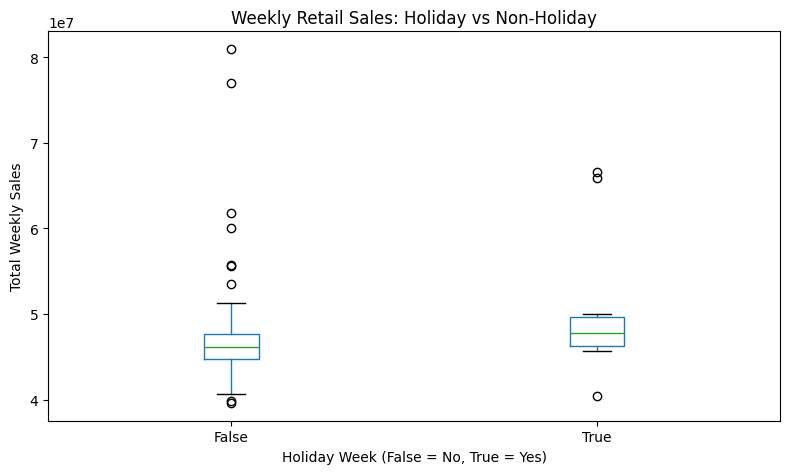

In [8]:
import matplotlib.pyplot as plt

ax = weekly_sales.boxplot(
    column="Weekly_Sales",
    by="IsHoliday",
    figsize=(8, 5),
    grid=False
)

ax.set_title("Weekly Retail Sales: Holiday vs Non-Holiday")
ax.set_xlabel("Holiday Week (False = No, True = Yes)")
ax.set_ylabel("Total Weekly Sales")

plt.suptitle("")
plt.tight_layout()
plt.show()

Visualisation Findings

The boxplot shows that holiday weeks have a slightly higher median sales value than non-holiday weeks.

outliers were in both groups, showing that certain weeks had unusually high or low sales numbers.

Several non-holiday weeks also featured exceptionally high sales, showing that peak performance is not restricted to holiday periods.

This visualisation supports the descriptive analysis but does not establish statistical significance.

## Business Requirement 3 - Final conclusion

This analysis looked at whether holiday weeks had genuinely different average total weekly sales compared to non-holiday weeks, and whether those differences actually mattered for business operations.

### Key Findings

- Holiday weeks averaged roughly 3.67 million higher in sales, marking a 7.84% increase over non-holiday weeks/

- The p-value returned from the welch's t-test was 0.2156, as this remained above the 0.05 significance threshold, it meant that we failed to reject the null hypothesis. 

There is not enough statistical evidence to conclude that mean weekly sales differ between holiday and non-holiday weeks.

Even so, the Cohen's d score of 0.683 shows a moderate-sized difference overall.

**Business Interpretation:**

While the observed sales gap holds potential commercial value for inventory control, labor scheduling, and seasonal planning, the statistical evidence remains insufficient to confirm a reliable difference.

Retail managers should factor in historical seasonal demand when planning resource allocation, whilst avoiding the assumption that holiday status alone explains increased sales.

## Limitations & Recommendations

Statical power was limited due to uneven sample sizes for holiday and non-holiday sales weeks.(holiday = 10 weeks and non-holiday = 133 weeks).

The t-test could not account for other factors that could sales, such as promotions, store characteristics, wider seasonal trends and relationships between holiday and non-holiday weeks. 

Further research using additional years of data and methods that account for seasonal patterns ould help determine whether this observed difference remains consistent over time.

**Overall:** Overall, while holiday weeks posted higher average sales and a moderate effect size, the difference fell short of statistical significance at the 5% level.
